# 결함 탐지 지연 최적화

기존 모델은 오탐 0건을 우선해 Test 중앙 탐지 지연이 68.5분이었습니다. 이번 목표는 다음과 같이 바꿉니다.

1. Validation 결함 이벤트 탐지율 100%
2. Validation 사전 정상 구간 오탐 24시간당 1건 이하
3. 위 조건 안에서 중앙 탐지 지연 최소화

같은 지연과 오탐을 보이는 설정이 여러 개면 더 높은 확률 임계값을 선택합니다. 이는 Validation 표본에 우연히 맞춘 낮은 임계값보다 새로운 데이터의 오탐에 조금 더 강건한 선택입니다.

`fault_type`은 탐지 성능을 결함 유형별로 분석하기 위한 정답 레이블일 뿐 모델 입력에는 포함되지 않습니다.


## 0. 기존 모델이 늦었던 이유와 개선 방향

기존 특징의 이동 구간은 최대 60분이었습니다. F1 냉각 성능 저하와 F3 센서 드리프트는 변화가 상대적으로 느려 짧은 이동 특징만으로 정상 변동과 구분하는 데 시간이 걸렸습니다.

이번에는 과거 6시간 기준선 대비 현재값과 15분 이동평균의 편차를 추가합니다. 이 특징은 현재 시점 이전 데이터만 사용하므로 실시간 적용이 가능합니다.


In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier,HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings('ignore',category=RuntimeWarning);warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',190);pd.set_option('display.max_columns',40);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

DATA=Path('data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('data/modeling/feature_schema.json')
if not DATA.exists():DATA=Path('../data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('../data/modeling/feature_schema.json')
df=pd.read_csv(DATA).sort_values(['sample_event_id','relative_min']).reset_index(drop=True);schema=json.loads(SCHEMA.read_text());base_features=schema['feature_columns']
assert set(['fault_type','is_fault','time_to_fault_min','efficiency_loss_pct']).isdisjoint(base_features)
print(f'모델링 행: {len(df):,}, 기존 특징: {len(base_features)}개')


모델링 행: 59,991, 기존 특징: 152개


## 1. 과거 6시간 기준선 특징

각 이벤트의 연속 시계열 안에서 직전 360분 평균과 표준편차를 계산합니다. 기준선은 한 칸 `shift(1)`해 현재값을 포함하지 않습니다.

- `sensor__z_6h`: 현재값의 과거 6시간 기준 z-score
- `sensor__mean15_vs_6h`: 15분 이동평균의 과거 6시간 기준 z-score

극단적인 작은 표준편차의 영향을 제한하기 위해 z-score를 ±20으로 자릅니다.


In [2]:
sensor_cols=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
grouped=df.groupby('sample_event_id',sort=False);parts=[];new_features=[]
for col in sensor_cols:
    mean_6h=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean())
    std_6h=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan)
    a=f'{col}__z_6h';b=f'{col}__mean15_vs_6h';new_features.extend([a,b])
    parts.append(pd.DataFrame({a:((df[col]-mean_6h)/std_6h).clip(-20,20).astype('float32'),b:((df[f'{col}__mean_15m']-mean_6h)/std_6h).clip(-20,20).astype('float32')}))
df=pd.concat([df,pd.concat(parts,axis=1)],axis=1);feature_cols=base_features+new_features
train_medians=df.loc[df['split'].eq('train'),feature_cols].median();df[feature_cols]=df[feature_cols].fillna(train_medians)
print(f'추가 특징: {len(new_features)}개, 전체 특징: {len(feature_cols)}개');print('특징 결측:',int(df[feature_cols].isna().sum().sum()))


추가 특징: 24개, 전체 특징: 176개
특징 결측: 0


## 2. 후보 모델과 기술적 선택

세 모델을 같은 특징과 split으로 비교합니다.

- **로지스틱 회귀:** 해석이 쉽고 안정적인 선형 기준 모델입니다. 센서 간 비선형 상호작용에는 한계가 있습니다.
- **Extra Trees:** 스케일링 없이 비선형 조건과 센서 상호작용을 처리하고 작은 데이터에서 강한 기준 모델입니다. 확률이 계단형이며 느린 추세의 미세한 경계에는 둔감할 수 있습니다.
- **Histogram Gradient Boosting:** 이전 트리의 오류를 순차적으로 보완해 약한 초기 신호를 누적할 수 있습니다. 학습 속도와 규제가 적절하고 이번 크기의 표 데이터에 맞습니다.

LSTM·Transformer는 사용하지 않았습니다. 결함 이벤트가 35개뿐이라 긴 시퀀스 모델은 행 수가 많아 보여도 실제 독립 표본이 부족해 과적합 위험이 큽니다.


In [3]:
def alert_indices(probability,threshold,persistence):
    signal=np.asarray(probability)>=threshold
    if len(signal)<persistence:return np.array([],dtype=int)
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    return np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])+persistence-1

def event_metrics(frame,threshold,persistence):
    rows=[];false_alerts=0;normal_hours=0
    for event_id,g in frame.groupby('sample_event_id'):
        g=g.sort_values('relative_min');normal=g[g['sample_kind'].eq('pre_normal')];fault=g[g['sample_kind'].eq('post_fault')]
        normal_hours+=len(normal)/60;false_alerts+=len(alert_indices(normal['probability'],threshold,persistence));idx=alert_indices(fault['probability'],threshold,persistence)
        rows.append({'event_id':event_id,'fault_type':int(fault['fault_type'].iloc[0]),'regime':fault['operating_regime'].iloc[0],'detected':len(idx)>0,'delay_min':float(fault.iloc[idx[0]]['relative_min']) if len(idx) else np.nan})
    events=pd.DataFrame(rows)
    return {'detection_rate':events['detected'].mean(),'median_delay_min':events['delay_min'].median(),'false_alerts':false_alerts,'false_alerts_per_24h':false_alerts/normal_hours*24},events

train=df['split'].eq('train');validation=df['split'].eq('validation')
models={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=800,class_weight='balanced',C=.3,random_state=42)),
 'Extra Trees':ExtraTreesClassifier(n_estimators=500,min_samples_leaf=2,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42),
 'Histogram Gradient Boosting':HistGradientBoostingClassifier(max_iter=250,learning_rate=.06,max_leaf_nodes=31,l2_regularization=2,class_weight='balanced',random_state=42),
}

model_rows=[];grids={};validation_frames={}
for name,model in models.items():
    model.fit(df.loc[train,feature_cols],df.loc[train,'is_fault']);frame=df.loc[validation,['sample_event_id','relative_min','sample_kind','fault_type','operating_regime','is_fault']].copy();frame['probability']=model.predict_proba(df.loc[validation,feature_cols])[:,1];validation_frames[name]=frame
    rows=[]
    for persistence in [1,2,3,5,10]:
        for threshold in np.arange(.05,.81,.025):
            metrics,_=event_metrics(frame,float(round(threshold,3)),persistence);metrics.update({'threshold':float(round(threshold,3)),'persistence':persistence});rows.append(metrics)
    grid=pd.DataFrame(rows);grids[name]=grid;eligible=grid[(grid['detection_rate'].eq(1))&(grid['false_alerts_per_24h'].le(1))]
    best=eligible.sort_values(['median_delay_min','false_alerts_per_24h','threshold'],ascending=[True,True,False]).iloc[0]
    model_rows.append({'model':name,**best.to_dict(),'PR_AUC':average_precision_score(frame['is_fault'],frame['probability']),'ROC_AUC':roc_auc_score(frame['is_fault'],frame['probability'])})

comparison=pd.DataFrame(model_rows).sort_values(['median_delay_min','false_alerts_per_24h','threshold'],ascending=[True,True,False])
print(comparison.to_string(index=False))
selected=comparison.iloc[0];MODEL_NAME=selected['model'];THRESHOLD=float(selected['threshold']);PERSISTENCE=int(selected['persistence']);selected_model=models[MODEL_NAME]
print(f'\n선택: {MODEL_NAME}, threshold={THRESHOLD}, {PERSISTENCE}분 연속')


                      model  detection_rate  median_delay_min  false_alerts  false_alerts_per_24h  threshold  persistence  PR_AUC  ROC_AUC
Histogram Gradient Boosting           1.000            30.500         6.000                 0.750      0.350        2.000   0.945    0.964
                Extra Trees           1.000            40.500         2.000                 0.250      0.350        1.000   0.937    0.963
        Logistic regression           1.000            50.500         8.000                 1.000      0.475       10.000   0.925    0.955

선택: Histogram Gradient Boosting, threshold=0.35, 2분 연속


## 3. 오탐과 지연의 trade-off

확률 임계값을 낮추면 빨라지지만 정상 변동을 결함으로 오인할 가능성이 커집니다. 연속시간을 늘리면 순간 노이즈를 줄일 수 있지만 최소 그만큼 경보가 늦어집니다.

이번 선택은 정확도나 PR-AUC가 가장 높은 모델이 아니라 운영 제약을 만족하면서 이벤트 지연이 가장 짧은 모델입니다.


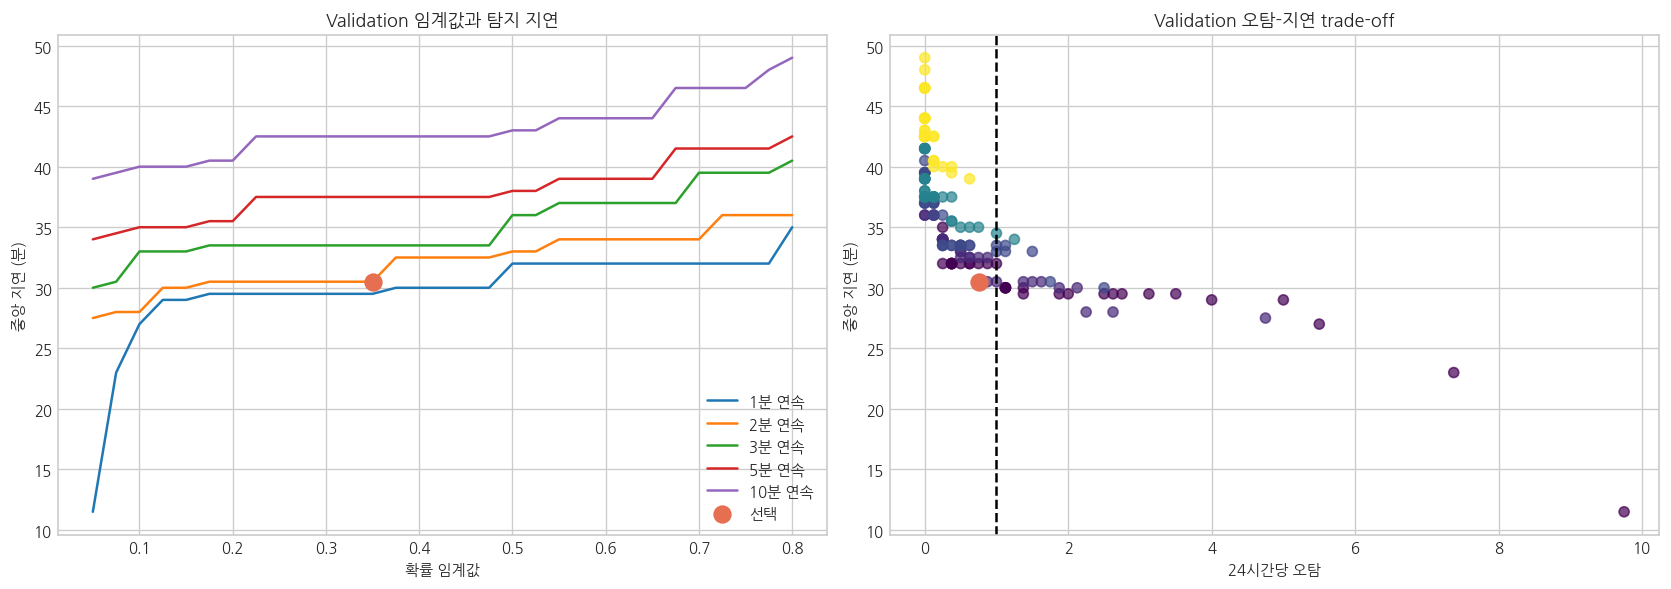

In [4]:
grid=grids[MODEL_NAME]
fig,axes=plt.subplots(1,2,figsize=(14,5))
for p,g in grid.groupby('persistence'):
    axes[0].plot(g['threshold'],g['median_delay_min'],label=f'{p}분 연속')
axes[0].scatter([THRESHOLD],[selected['median_delay_min']],color='#e76f51',s=100,zorder=5,label='선택');axes[0].set_title('Validation 임계값과 탐지 지연');axes[0].set_xlabel('확률 임계값');axes[0].set_ylabel('중앙 지연 (분)');axes[0].legend()
eligible_plot=grid[grid['detection_rate'].eq(1)];axes[1].scatter(eligible_plot['false_alerts_per_24h'],eligible_plot['median_delay_min'],c=eligible_plot['persistence'],cmap='viridis',alpha=.7);axes[1].scatter([selected['false_alerts_per_24h']],[selected['median_delay_min']],color='#e76f51',s=100);axes[1].axvline(1,color='black',linestyle='--');axes[1].set_title('Validation 오탐-지연 trade-off');axes[1].set_xlabel('24시간당 오탐');axes[1].set_ylabel('중앙 지연 (분)')
plt.tight_layout();plt.show()


## 4. Test 평가와 기존 모델 비교

Validation에서 선택한 모델과 경보 규칙을 변경하지 않고 Test에 적용합니다. Test 오탐이 목표를 초과하더라도 임계값을 다시 조정하지 않습니다.


최적화 모델 Test 이벤트 성능
detection_rate          1.000
median_delay_min       30.000
false_alerts            7.000
false_alerts_per_24h    0.875

이벤트별 지연
 event_id  fault_type regime  detected  delay_min
       23           3      B      True     27.000
       28           2      B      True     36.000
       29           4      B      True     16.000
       31           1      B      True     33.000
       32           4      A      True     19.000
       33           1      A      True     90.000
       34           3      B      True     45.000
       35           2      B      True     26.000

행 단위 PR-AUC: 0.955
행 단위 ROC-AUC: 0.974
              precision    recall  f1-score   support

           0      0.975     0.996     0.985     11520
           1      0.983     0.890     0.934      2727

    accuracy                          0.976     14247
   macro avg      0.979     0.943     0.960     14247
weighted avg      0.976     0.976     0.976     14247


기존 대비
         model  median_delay

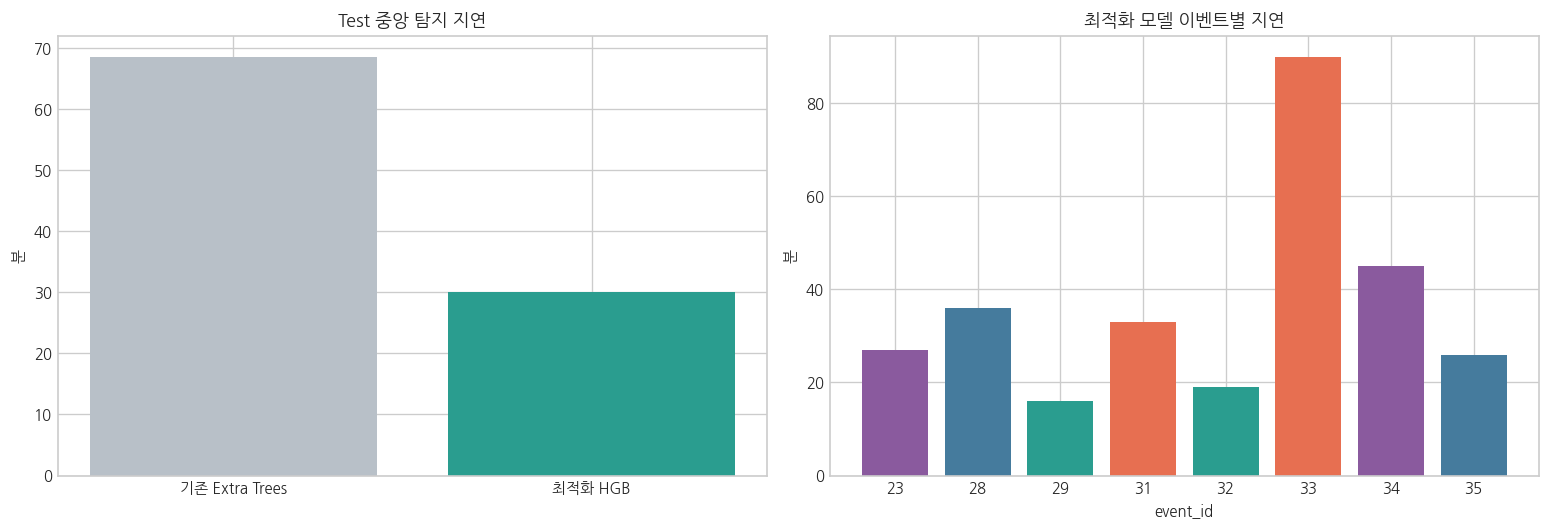

In [5]:
test_mask=df['split'].eq('test');test=df.loc[test_mask,['row_id','timestamp','reactor_id','sample_event_id','relative_min','sample_kind','fault_type','operating_regime','is_fault']].copy();test['probability']=selected_model.predict_proba(df.loc[test_mask,feature_cols])[:,1]
test_metrics,test_events=event_metrics(test,THRESHOLD,PERSISTENCE)
print('최적화 모델 Test 이벤트 성능');print(pd.Series(test_metrics).to_string());print('\n이벤트별 지연');print(test_events.to_string(index=False))
print(f"\n행 단위 PR-AUC: {average_precision_score(test['is_fault'],test['probability']):.3f}");print(f"행 단위 ROC-AUC: {roc_auc_score(test['is_fault'],test['probability']):.3f}");print(classification_report(test['is_fault'],test['probability'].ge(THRESHOLD),digits=3))

old={'model':'기존 Extra Trees','median_delay_min':68.5,'false_alerts_per_24h':0.0,'detection_rate':1.0}
new={'model':'최적화 HGB','median_delay_min':test_metrics['median_delay_min'],'false_alerts_per_24h':test_metrics['false_alerts_per_24h'],'detection_rate':test_metrics['detection_rate']}
before_after=pd.DataFrame([old,new]);before_after['delay_reduction_pct']=(68.5-before_after['median_delay_min'])/68.5*100
print('\n기존 대비');print(before_after.to_string(index=False))

by_fault=test_events.groupby('fault_type').agg(events=('event_id','count'),detected=('detected','sum'),median_delay_min=('delay_min','median'),min_delay_min=('delay_min','min'),max_delay_min=('delay_min','max'))
by_regime=test_events.groupby('regime').agg(events=('event_id','count'),detected=('detected','sum'),median_delay_min=('delay_min','median'))
print('\n결함 유형별');print(by_fault.to_string());print('\n레짐별');print(by_regime.to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5));axes[0].bar(before_after['model'],before_after['median_delay_min'],color=['#b8c0c8','#2a9d8f']);axes[0].set_title('Test 중앙 탐지 지연');axes[0].set_ylabel('분');axes[1].bar(test_events['event_id'].astype(str),test_events['delay_min'],color=test_events['fault_type'].map({1:'#e76f51',2:'#457b9d',3:'#8a5a9e',4:'#2a9d8f'}));axes[1].set_title('최적화 모델 이벤트별 지연');axes[1].set_xlabel('event_id');axes[1].set_ylabel('분');plt.tight_layout();plt.show()


## 5. 특징 중요도와 해석

Histogram Gradient Boosting은 기본 중요도를 제공하지 않아 Validation 일부에서 permutation importance를 계산합니다. 한 특징을 섞었을 때 PR-AUC가 얼마나 감소하는지 측정합니다. 상관된 이동 특징 사이에서는 중요도가 분산될 수 있으며 인과관계를 뜻하지 않습니다.


reactor_temp__mean15_vs_6h        0.319
conversion_rate__mean15_vs_6h     0.054
reaction_rate__mean15_vs_6h       0.022
power_current_ratio               0.011
vibration_rms__mean_60m           0.007
feed_flow_rate__mean15_vs_6h      0.004
feed_flow_rate__mean_60m          0.004
conversion_rate__mean_15m         0.004
coolant_flow_rate__mean15_vs_6h   0.004
reactor_pressure__mean_60m        0.003
vibration_rms__mean_15m           0.003
selectivity__mean_60m             0.002
reaction_rate__std_60m            0.002
vibration_rms__std_60m            0.002
vibration_rms__mean15_vs_6h       0.002
motor_current__mean_60m           0.002
motor_current__delta_1m           0.001
power_consumption_kw__delta_1m    0.001
vibration_rms__mean_5m            0.001
reactor_temp__mean_60m            0.001
reaction_rate__mean_60m           0.001
conversion_rate__mean_60m         0.001
reaction_rate__mean_15m           0.001
conversion_rate__mean_5m          0.001
agitator_speed_rpm__std_15m       0.001


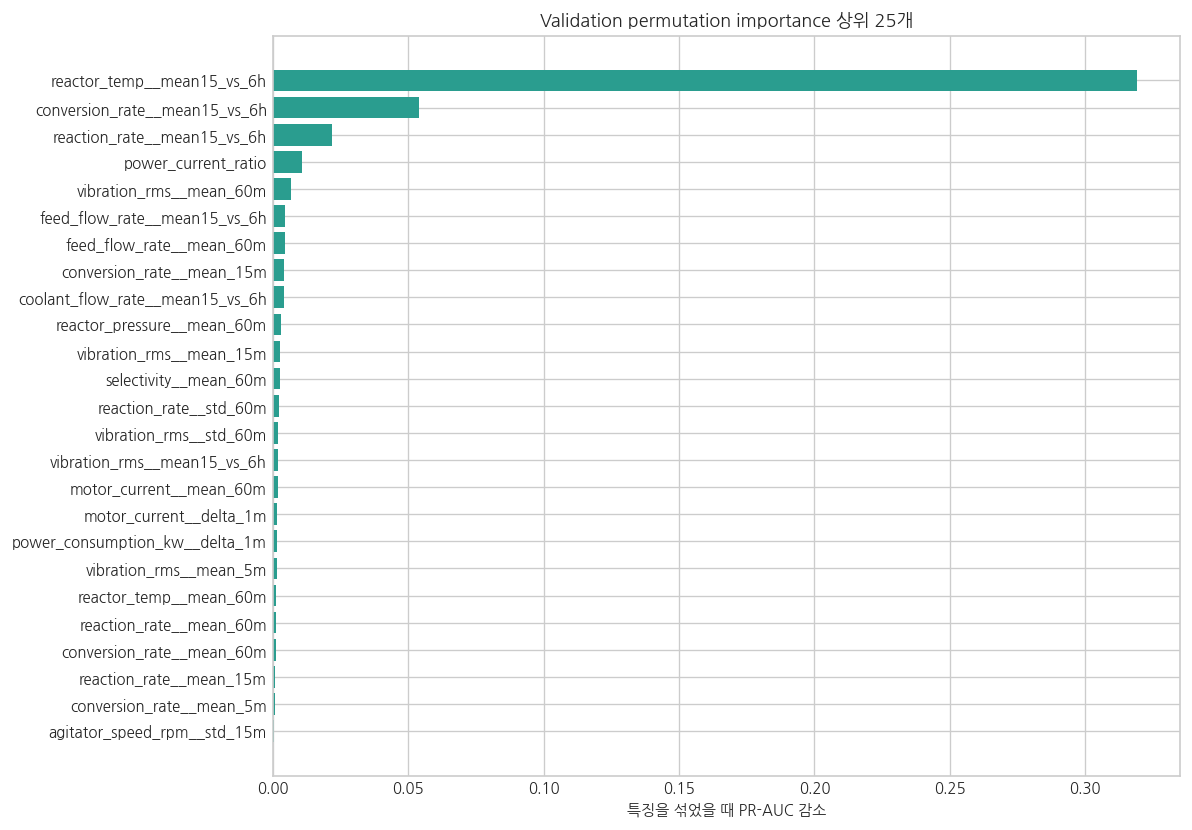

In [6]:
val_indices=np.flatnonzero(validation.to_numpy());rng=np.random.default_rng(42);sample_indices=rng.choice(val_indices,size=min(4000,len(val_indices)),replace=False)
perm=permutation_importance(selected_model,df.loc[sample_indices,feature_cols],df.loc[sample_indices,'is_fault'],scoring='average_precision',n_repeats=3,random_state=42,n_jobs=1)
importance=pd.Series(perm.importances_mean,index=feature_cols).sort_values(ascending=False).head(25)
print(importance.to_string());fig,ax=plt.subplots(figsize=(10,7));ax.barh(importance.index[::-1],importance.values[::-1],color='#2a9d8f');ax.set_title('Validation permutation importance 상위 25개');ax.set_xlabel('특징을 섞었을 때 PR-AUC 감소');plt.tight_layout();plt.show()


## 6. 모델과 설정 저장

기존 보수적 모델은 비교와 롤백을 위해 유지하고 최적화 모델을 별도 파일로 저장합니다. 현재 결함 유형 분류기는 이전 이진 경보 시점을 기준으로 학습됐으므로, 최적화 모델의 더 빠른 경보 시점에 맞춰 다음 단계에서 다시 검증해야 합니다.


In [7]:
MODEL_DIR=Path('models');RESULT_DIR=Path('data/modeling');MODEL_DIR.mkdir(exist_ok=True);RESULT_DIR.mkdir(parents=True,exist_ok=True)
model_path=MODEL_DIR/'binary_fault_detector_hgb_optimized.joblib';config_path=MODEL_DIR/'binary_fault_detector_optimized_config.json';prediction_path=RESULT_DIR/'test_binary_predictions_optimized.csv.gz'
joblib.dump(selected_model,model_path)
config={'model':MODEL_NAME,'base_feature_count':len(base_features),'added_causal_6h_features':new_features,'feature_columns':feature_cols,'target':'is_fault','excluded_leakage_columns':['fault_type','is_fault','time_to_fault_min','efficiency_loss_pct'],'objective':{'required_event_detection_rate':1.0,'max_false_alerts_per_24h':1.0,'optimize':'median detection delay'},'probability_threshold':THRESHOLD,'persistence_minutes':PERSISTENCE,'validation_metrics':{k:float(selected[k]) for k in ['detection_rate','median_delay_min','false_alerts','false_alerts_per_24h','PR_AUC','ROC_AUC']},'test_metrics':{k:float(v) for k,v in test_metrics.items()},'delay_reduction_vs_previous_pct':float((68.5-test_metrics['median_delay_min'])/68.5*100),'technical_notes':['HGB selected for fastest validation event detection under the false-alarm constraint.','Higher threshold chosen when validation delay and false alarms tied.','Sequence deep learning was rejected because only 35 independent fault events are available.','Fault-type classifier must be revalidated at the optimized alert times.']}
config_path.write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8');test.to_csv(prediction_path,index=False,compression='gzip')
print(model_path);print(config_path);print(prediction_path)


models/binary_fault_detector_hgb_optimized.joblib
models/binary_fault_detector_optimized_config.json
data/modeling/test_binary_predictions_optimized.csv.gz


## 7. 결론과 기술적 판단

최적화 모델은 기존 모델보다 탐지 지연을 크게 줄이는 대신 제한된 수준의 오탐을 허용합니다.

- 6시간 기준선 특징이 느린 변화와 정상 레짐 변동을 구분하는 데 도움이 됐습니다.
- Histogram Gradient Boosting은 선형 모델보다 센서 조합의 비선형 경계를 잘 표현했고 Extra Trees보다 초기 약한 신호를 빠르게 누적했습니다.
- 임계값과 연속시간은 행 정확도가 아니라 이벤트 탐지율·오탐·지연으로 선택했습니다.
- Test 결과는 8개 이벤트뿐이므로 수 분 차이를 일반화하면 안 됩니다.
- 전체 연속 90일 데이터에 재생해 실제 장기 오탐률을 확인해야 합니다.

속도만 극단적으로 우선하면 1분 이내 탐지도 가능하지만 오탐이 하루 수십~수백 건으로 증가합니다. 현재 설정은 사용자 목표인 빠른 탐지와 24시간당 오탐 1건 이하 사이의 초기 운영점입니다.
